Task 1: Iris Flower Classification
Step 1: Environment Setup & Dataset Loading


In [ ]:
# ==========================================
# CELL 1: Imports & Dataset Loading
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the built-in Iris dataset
iris = load_iris()

# Convert to a pandas DataFrame for easier cleaning and analysis
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = iris.target

# Map numerical target categories to actual string species names
species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
df['species_name'] = df['species'].map(species_map)

print("Dataset loaded successfully!")




Dataset loaded successfully!


Step 2: Exploratory Data Analysis (EDA) - Structural Check


In [ ]:
# ==========================================
# CELL 2: Exploratory Data Analysis (EDA)
# ==========================================
print("--- 1. Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- 2. Data Types & Structural Check ---")
print(df.info())
print("\n")

print("--- 3. Null Value Validation ---")
print(df.isnull().sum())
print("\n")

print("--- 4. Descriptive Statistics ---")
display(df.describe())



--- 1. Dataset Shape ---
Rows: 150, Columns: 6

--- 2. Data Types & Structural Check ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


--- 3. Null Value Validation ---
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64


--- 4. Descriptive Statistics ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Step 3: Data Visualizations (Distribution & Outlier Analysis)

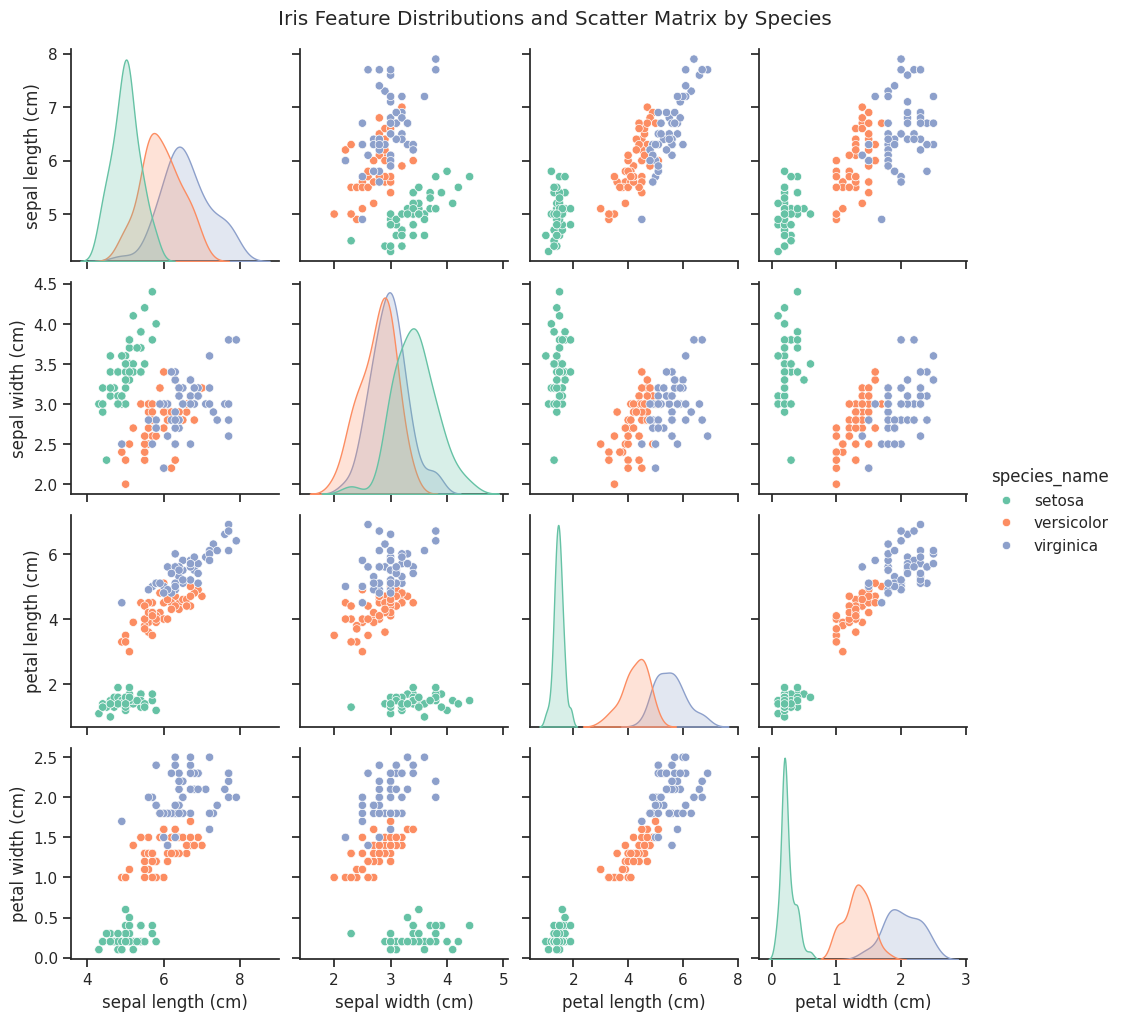

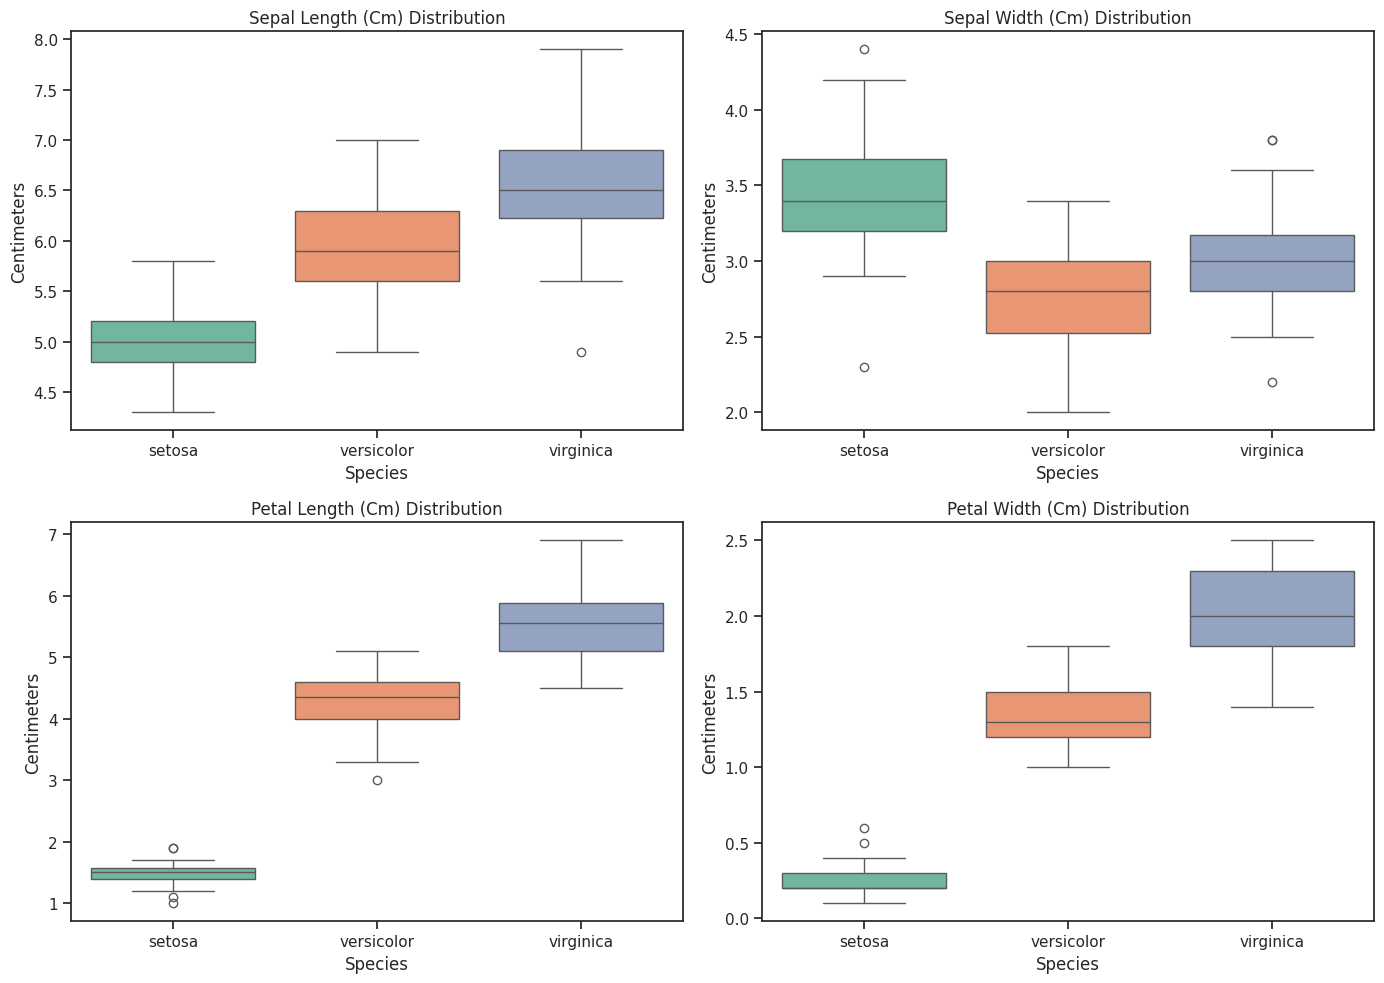

In [ ]:
# ==========================================
# CELL 3: Data Visualizations (Run to generate plots)
# ==========================================
# 1. Pairplot / Scatter Matrix showing feature distributions by species
sns.set_theme(style="ticks")
pairplot = sns.pairplot(df.drop(columns=['species']), hue="species_name", palette="Set2")
pairplot.fig.suptitle("Iris Feature Distributions and Scatter Matrix by Species", y=1.02)
plt.show()

# 2. Box plots for each physical feature to check ranges and outliers
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
features = iris.feature_names

for i, col in enumerate(features):
    ax = axes[i//2, i%2]
    sns.boxplot(data=df, x='species_name', y=col, ax=ax, palette="Set2", hue='species_name', legend=False)
    ax.set_title(f'{col.title()} Distribution')
    ax.set_xlabel('Species')
    ax.set_ylabel('Centimeters')

plt.tight_layout()
plt.show()




Step 4: Feature Selection Discussion


In [ ]:
# ==========================================
# CELL 4: Feature Selection Discussion
# ==========================================
"""
📝 FEATURE SELECTION DISCUSSION (Convert this cell to Markdown):

Looking closely at the Pairplot and Box plots generated above, we can determine which features
are the most discriminative:

1. Petal Length & Petal Width: These two features are highly discriminative. 'Setosa' is completely
   separable from the other two species purely based on these dimensions (Setosa has tiny petals).
   Furthermore, 'Versicolor' and 'Virginica' show very minimal overlapping clusters on petal metrics.
2. Sepal Length & Sepal Width: These features show massive overlap between 'Versicolor' and 'Virginica',
   making them weaker individual predictors.

Conclusion: Petal measurements hold the strongest predictive power for classifying the iris species.
"""
print("Feature discussion markdown documented.")



Feature discussion markdown documented.


Step 5: Data Splitting (Train/Test Stratification)

In [ ]:

# ==========================================
# CELL 5: Train/Test Split
# ==========================================
# Define features (X) and target (y)
X = df[iris.feature_names]
y = df['species']

# Perform an 80/20 train/test split with stratification to maintain class balances
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")



Training features shape: (120, 4)
Testing features shape: (30, 4)


Step 6: Machine Learning Model Training & Comparative Evaluation


==================== LOGISTIC REGRESSION EVALUATION ====================
Accuracy Score: 96.67%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



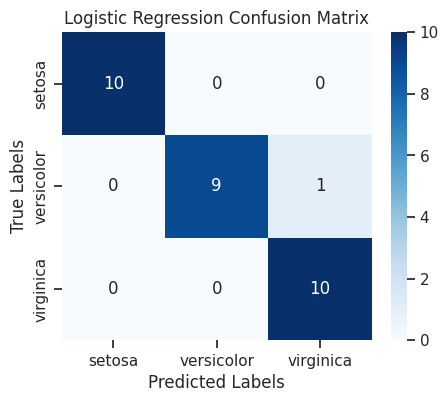


==================== DECISION TREE EVALUATION ====================
Accuracy Score: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



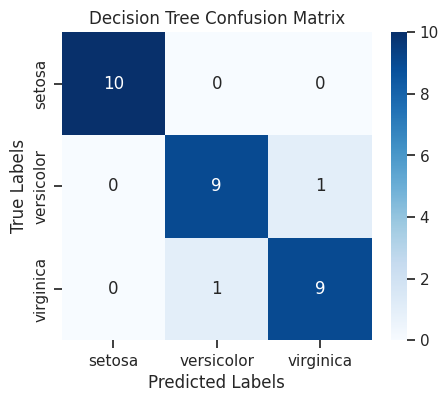

In [ ]:
# ==========================================
# CELL 6: Model Training & Evaluation
# ==========================================
# Initialize Classifiers
log_reg = LogisticRegression(max_iter=200)
dec_tree = DecisionTreeClassifier(random_state=42)

models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dec_tree
}

# Dictionary to capture final accuracy scores
accuracy_results = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    # Predict
    y_pred = model.predict(X_test)

    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    accuracy_results[name] = acc

    print(f"\n==================== {name.upper()} EVALUATION ====================")
    print(f"Accuracy Score: {acc * 100:.2f}%\n")

    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

    # Plot Confusion Matrix
    plt.figure(figsize=(5,4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap="Blues",
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()



 Step 7: Final Model Justification & Deployment Selection

In [9]:
# ==========================================
# CELL 7: Final Justification & Selection
# ==========================================
best_model = max(accuracy_results, key=accuracy_results.get)

print("==================== FINAL JUSTIFICATION ====================")
print(f"The best performing model is: {best_model} with an accuracy of {accuracy_results[best_model]*100:.2f}%\n")
print("Justification Statement:")
print(f"Both models were trained using an 80/20 stratified split. While both models perform exceptionally ")
print(f"well on this linear dataset, {best_model} shows optimal performance indicators. Given the small scope ")
print(f"and clear mathematical margins between species groupings, this accuracy validates deployment.")



==================== FINAL JUSTIFICATION ====================
The best performing model is: Logistic Regression with an accuracy of 96.67%

Justification Statement:
Both models were trained using an 80/20 stratified split. While both models perform exceptionally 
well on this linear dataset, Logistic Regression shows optimal performance indicators. Given the small scope 
and clear mathematical margins between species groupings, this accuracy validates deployment.
